The objective of this notebook is to explore historical FMCG sales data to identify trends, seasonal patterns, and variations in product demand.
The analysis focuses on understanding sales performance across time and identifying patterns that may influence future demand forecasting.
# Key Areas of Analysis
1. Overall sales performance and distribution.
2. Daily and monthly sales trends.
3. Seasonal variations in demand.
4. Sales patterns across product categories and distribution channels.
5. Potential demand drivers relevant to forecasting.


In [1]:
#import libraraies for data exploration and anlysis.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the  dataset
df = pd.read_csv(
    "../data/fmcg_sales_cleaned.csv",
    parse_dates=["date"]
)

In [3]:
#number of rows and columns in the dataset.
df.shape

(1100000, 33)

In [4]:
# Verify the date column's data type
df['date'].dtype

dtype('<M8[us]')

In [5]:
# Calculate overall sales performance
total_units = df['units_sold'].sum()
total_revenue = df['net_sales'].sum()
average_units = df['units_sold'].mean()

print(f"Total units sold: {total_units:,.0f}")
print(f"Total net sales: {total_revenue:,.2f}")
print(f"Average units sold per observation: {average_units:.2f}")

Total units sold: 65,115,982
Total net sales: 472,946,452.83
Average units sold per observation: 59.20


The average units sold per observation should not be interpreted as average daily product demand, since the dataset contains observations across multiple products, stores, and distribution channels.

In [6]:
# Calculate total units sold for each date
daily_sales = (
    df.groupby('date')['units_sold']
    .sum()
    .sort_index()
)
# Display the first five days
daily_sales.head()

date
2021-01-01    53924
2021-01-02    68546
2021-01-03    68066
2021-01-04    55802
2021-01-05    53234
Name: units_sold, dtype: int64

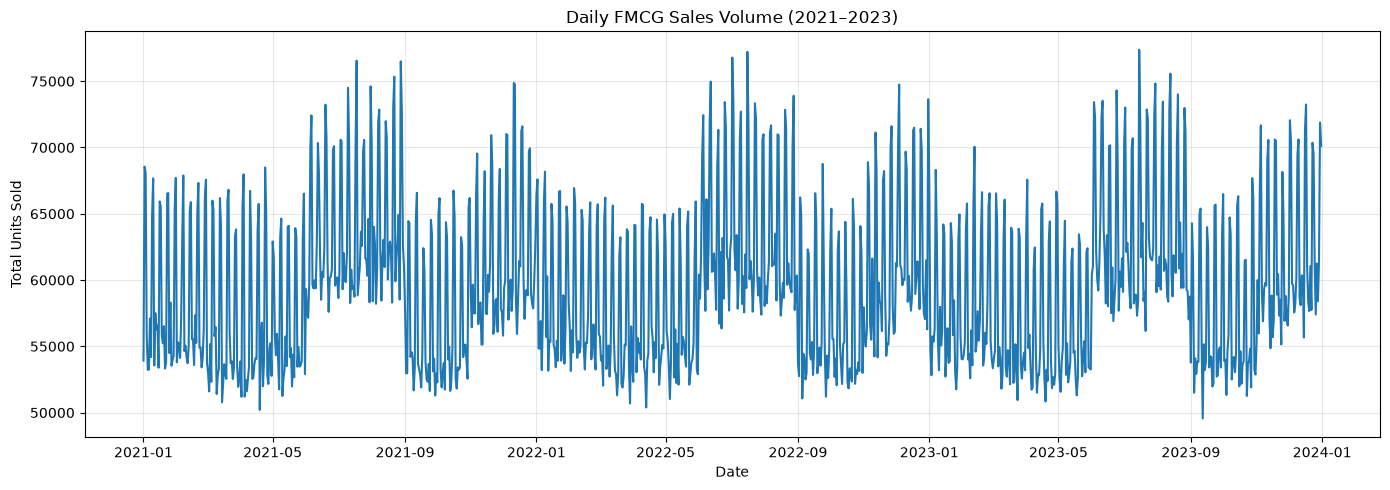

In [7]:
# Visualize daily sales trends
plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)

plt.title('Daily FMCG Sales Volume (2021–2023)')
plt.xlabel('Date')
plt.ylabel('Total Units Sold')

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

The daily sales line graph reveals substantial fluctuations in FMCG sales volumes throughout the three-year period.
Several recurring patterns are visually clear, with relatively high sales volumes around the middle of each year and lower sales levels during certain subsequent months.
Frequent short-term spikes are also observed, suggesting considerable day-to-day variation in recorded sales.
Despite these fluctuations, there is no clear sustained upward or downward trend across the entire observation period.
The repeated patterns suggest the possible presence of seasonality. However, further analysis using monthly aggregation is necessary to evaluate these patterns more clearly.



In [8]:
# Calculate average daily sales for each calendar month
monthly_sales = daily_sales.resample('MS').mean()

# Display the first 12 months
monthly_sales.head(12)

date
2021-01-01    58735.967742
2021-02-01    58130.285714
2021-03-01    56349.451613
2021-04-01    56517.266667
2021-05-01    56973.935484
2021-06-01    62778.066667
2021-07-01    63835.258065
2021-08-01    64603.935484
2021-09-01    56136.333333
2021-10-01    56997.290323
2021-11-01    60426.866667
2021-12-01    62269.903226
Freq: MS, Name: units_sold, dtype: float64

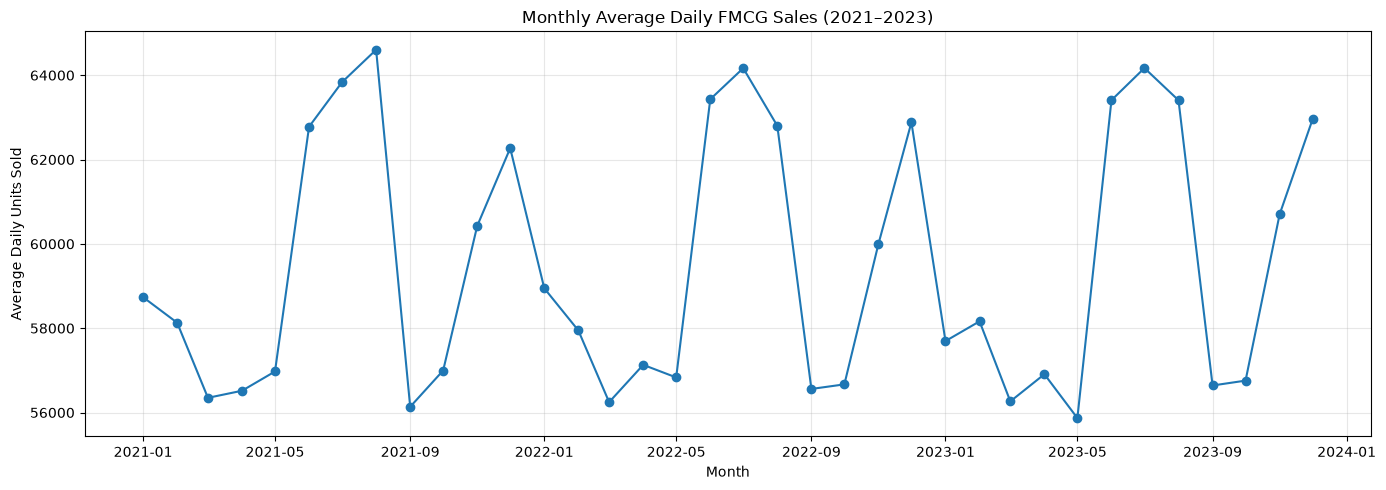

In [9]:
# Visualize monthly average daily sales
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Average Daily FMCG Sales (2021–2023)')
plt.xlabel('Month')
plt.ylabel('Average Daily Units Sold')

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

The monthly average daily sales graph reveals a recurring pattern across the three-year observation period.
Sales volumes generally increase during June, July, and August, with peak average daily sales reaching approximately 64,000 units. This pattern is visible in 2021, 2022, and 2023.
A pronounced decline occurs around September in each year, followed by a recovery toward November and December.
These repeated fluctuations provide visual evidence of annual seasonality in aggregate FMCG sales.
The findings suggest that calendar-based variables, particularly month of the year, may be useful predictors when developing demand forecasting models.

In [10]:
# Create a DataFrame from the monthly sales series
seasonal_sales = monthly_sales.reset_index()

# Extract year and month
seasonal_sales['year'] = seasonal_sales['date'].dt.year
seasonal_sales['month'] = seasonal_sales['date'].dt.month

# Display the first five observations
seasonal_sales.head()

,date,units_sold,year,month
0,2021-01-01,58735.967742,2021,1
1,2021-02-01,58130.285714,2021,2
2,2021-03-01,56349.451613,2021,3
3,2021-04-01,56517.266667,2021,4
4,2021-05-01,56973.935484,2021,5


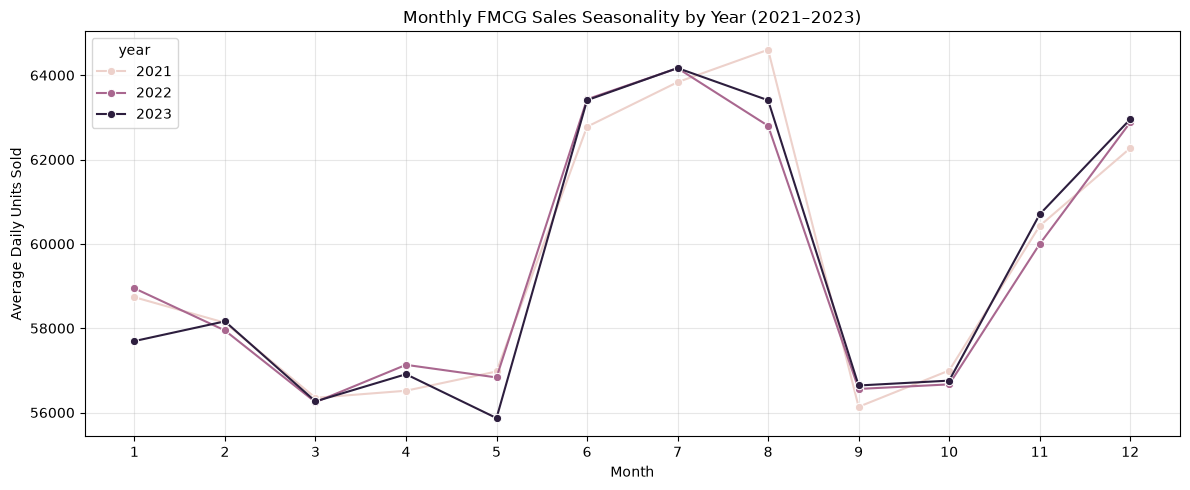

In [11]:
# Compare monthly sales patterns across the three years
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=seasonal_sales,
    x='month',
    y='units_sold',
    hue='year',
    marker='o'
)

plt.title('Monthly FMCG Sales Seasonality by Year (2021–2023)')
plt.xlabel('Month')
plt.ylabel('Average Daily Units Sold')

plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

The three annual sales profiles exhibit similar patterns, providing strong visual evidence of recurring annual seasonality in aggregate FMCG sales.
Average daily sales increase substantially between May and June, remain relatively elevated during July and August, and decline sharply in September.
A further increase in sales is observed during November and December across all three years.
Although the overall seasonal patterns are similar, minor differences in monthly sales volumes occur between years.
These findings suggest that month of the year may be an important predictor of aggregate sales volume.
However, the analysis is descriptive, and further investigation is required to determine whether these seasonal patterns are consistent across individual products, categories, and distribution channels.

In [12]:
# Calculate total units sold by product category
category_sales = (
    df.groupby('category')['units_sold']
    .sum()
    .sort_values(ascending=False)
)
category_sales

category
Beverages        18090386
Snacks           16724604
Personal Care    10799580
Dairy            10224202
Home Care         9277210
Name: units_sold, dtype: int64

In [13]:
# Calculate percentage contribution of each category
category_percentage = (
    category_sales / category_sales.sum()
) * 100
category_percentage.round(2)

category
Beverages        27.78
Snacks           25.68
Personal Care    16.59
Dairy            15.70
Home Care        14.25
Name: units_sold, dtype: float64

Beverages recorded the highest sales volume, with 18,090,386 units sold, accounting for approximately 27.78% of total sales. Snacks followed with 16,724,604 units, representing approximately 25.68%.
Together, Beverages and Snacks contributed approximately 53.46% of total units sold, indicating that these two categories accounted for more than half of the recorded sales volume.
Personal Care contributed approximately 16.59%, followed by Dairy at 15.70%. Home Care recorded the lowest sales volume, accounting for approximately 14.25% of total units sold.
Overall, the findings indicate that sales volumes vary across product categories, with Beverages and Snacks contributing the largest shares.
However, these differences may be influenced by the number of products, stores, and sales observations within each category.

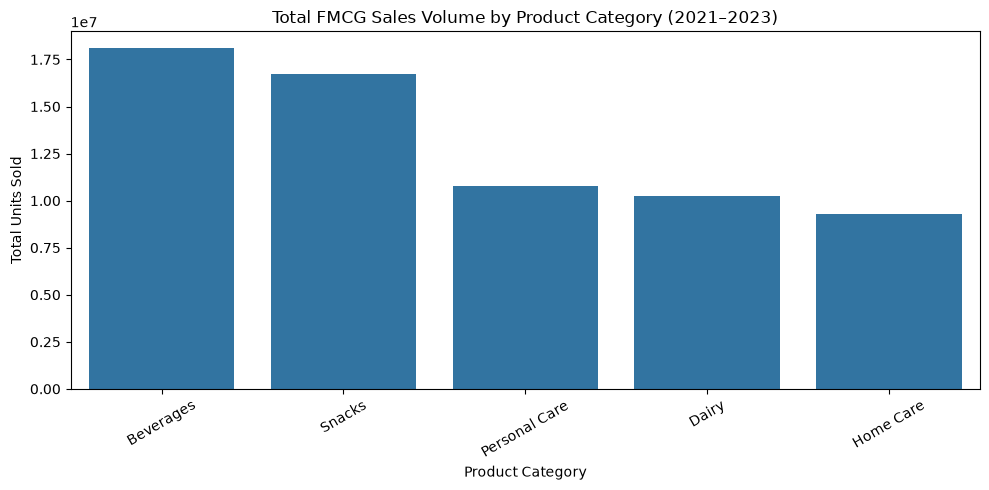

In [14]:
# Visualize total units sold by product category
plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title('Total FMCG Sales Volume by Product Category (2021–2023)')
plt.xlabel('Product Category')
plt.ylabel('Total Units Sold')

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [15]:
# Calculate total units sold by distribution channel
channel_sales = (
    df.groupby('channel')['units_sold']
    .sum()
    .sort_values(ascending=False)
)
channel_sales

channel
Hypermarket    35341421
E-commerce     15647980
Supermarket    12396289
Convenience     1730292
Name: units_sold, dtype: int64

In [16]:
# Calculate each channel's percentage contribution
channel_percentage = (
    channel_sales / channel_sales.sum()
) * 100
channel_percentage.round(2)

channel
Hypermarket    54.27
E-commerce     24.03
Supermarket    19.04
Convenience     2.66
Name: units_sold, dtype: float64

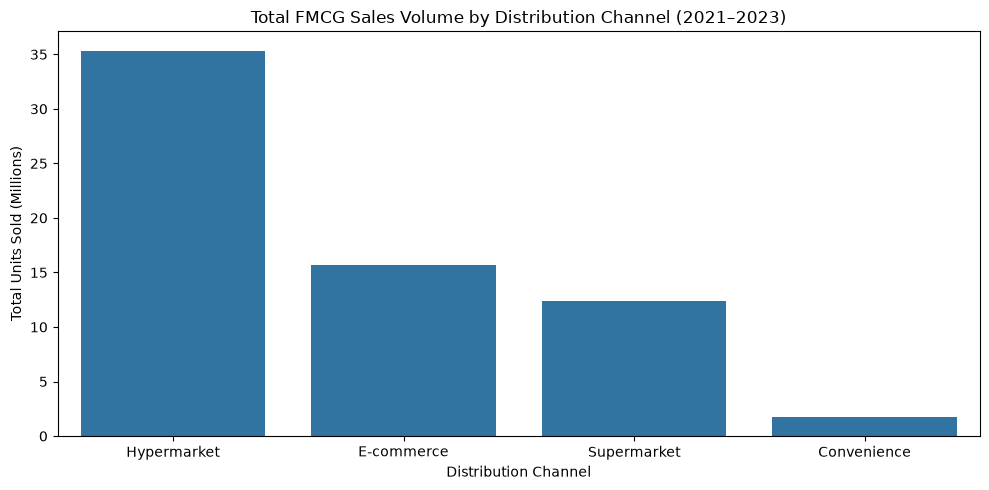

In [17]:
# Visualize total units sold by distribution channel
plt.figure(figsize=(10, 5))

sns.barplot(
    x=channel_sales.index,
    y=channel_sales.values / 1_000_000
)

plt.title('Total FMCG Sales Volume by Distribution Channel (2021–2023)')
plt.xlabel('Distribution Channel')
plt.ylabel('Total Units Sold (Millions)')

plt.tight_layout()
plt.show()

These findings indicate that recorded FMCG sales are heavily concentrated in the Hypermarket channel.
However, differences in total sales volume may be influenced by the number of stores, products, and observations represented within each channel. Therefore, further analysis is required before concluding that one channel generates higher demand per store or performs more efficiently than another.

In [18]:
# Calculate average daily sales by day of the week
weekday_sales = daily_sales.groupby(
    daily_sales.index.dayofweek
).mean()

# Rename numerical weekday labels
weekday_sales.index = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]
weekday_sales.round(2)

Monday       56211.68
Tuesday      56351.19
Wednesday    56287.04
Thursday     56395.76
Friday       56135.08
Saturday     67344.86
Sunday       67460.55
Name: units_sold, dtype: float64

In [19]:
# Calculate average weekday and weekend sales
weekday_average = weekday_sales.iloc[:5].mean()
weekend_average = weekday_sales.iloc[5:].mean()

# Calculate the percentage difference
weekend_increase = (
    (weekend_average - weekday_average) / weekday_average
) * 100

print(f"Average weekday sales: {weekday_average:,.2f}")
print(f"Average weekend sales: {weekend_average:,.2f}")
print(f"Weekend sales increase: {weekend_increase:.2f}%")

Average weekday sales: 56,276.15
Average weekend sales: 67,402.70
Weekend sales increase: 19.77%


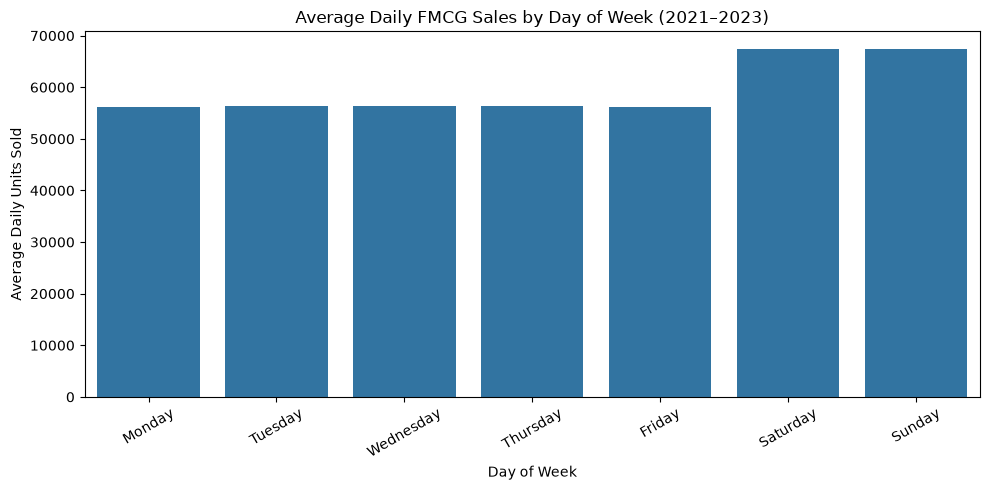

In [20]:
# Visualize average daily sales by weekday
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title('Average Daily FMCG Sales by Day of Week (2021–2023)')
plt.xlabel('Day of Week')
plt.ylabel('Average Daily Units Sold')

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

The results indicate that average sales volumes are relatively consistent from Monday through Friday, ranging from approximately 56,135 to 56,396 units per day.
In contrast, weekends record substantially higher sales volumes. Average weekday sales were approximately 56,276 units, compared with 67,403 units during weekends.
This represents an increase of approximately 19.77% in average daily sales volume during weekends.
Sunday recorded the highest average daily sales, while Friday recorded the lowest.
These findings provide descriptive evidence of weekly seasonality in aggregate FMCG sales and suggest that weekday and weekend indicators may be useful predictors in future demand forecasting models.